# Analysis 9: How did Netflix's catalog grow, and did the quality of what it added change?

**Business question.** Between 2016 and 2021, which countries and genres drove Netflix's catalog growth, and did the titles it added get better or worse on IMDb?

**Data.** The Netflix catalog as of September 2021, joined to IMDb ratings (84.8% of titles matched, see `reports/data_quality.md`). Ratings are compared only for titles with at least 1,000 IMDb votes, because ratings with fewer votes are noisy.

**Two scope notes.**

- The catalog is a snapshot. Titles that were added and then removed before September 2021 are not in it, so additions in earlier years are undercounted, and the earlier titles that remain are the ones Netflix chose to keep.
- IMDb ratings are from October 2026, not from the time each title was added.

**Method.** Shares of additions by production country and genre over time; IMDb ratings by year added, with a linear regression controlling for type, log votes, whether the title was a recent release, and genre.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from streampulse.charts import COUNTRY_COLORS, SECONDARY_INK, SINGLE_SERIES_COLOR, TYPE_COLORS, apply_chart_style
from streampulse.database import connect

MIN_IMDB_VOTES = 1000
PRODUCTION_COUNTRY_CODES = {"India": "IN", "United States": "US", "United Kingdom": "GB"}

apply_chart_style()
with connect() as connection:
    netflix = connection.execute("SELECT * FROM netflix_titles").df()

netflix = netflix.dropna(subset=["date_added"]).copy()
netflix["year_added"] = pd.to_datetime(netflix["date_added"]).dt.year.astype(int)
# A title added within a year of its release counts as a recent release; older ones are back catalogue.
netflix["recent_release"] = (netflix["year_added"] - netflix["release_year"]) <= 1
# Many titles list several production countries; the first is usually the main one.
netflix["main_country"] = netflix["country"].str.split(",").str[0].str.strip()
study_years = netflix[netflix["year_added"].between(2016, 2021)]
print(f"{len(netflix):,} titles with a date added; {len(study_years):,} added 2016 to 2021")

8,792 titles with a date added; 8,654 added 2016 to 2021


## 1. Where the additions came from

Share of each year's additions by main production country. India, the US and the UK are shown; all other countries are grouped.

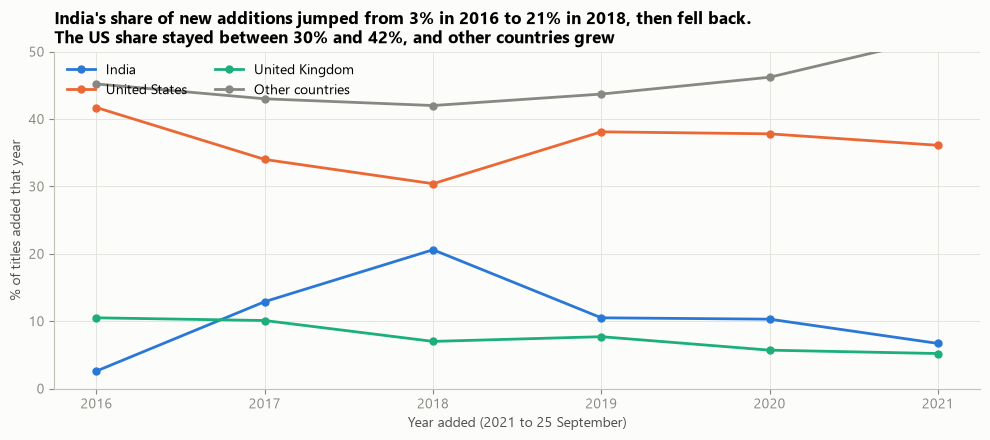

main_country,India,Other countries,United Kingdom,United States,titles_added
year_added,,,,,
2016,2.6,45.2,10.5,41.7,429
2017,12.9,43.0,10.1,34.0,1188
2018,20.6,42.0,7.0,30.4,1649
2019,10.5,43.7,7.7,38.1,2015
2020,10.3,46.2,5.7,37.8,1879
2021,6.7,52.1,5.2,36.1,1494


In [2]:
country_group = study_years["main_country"].where(study_years["main_country"].isin(PRODUCTION_COUNTRY_CODES), "Other countries")
country_share = (100 * pd.crosstab(study_years["year_added"], country_group.fillna("Unknown"), normalize="index")).round(1)

fig, ax = plt.subplots(figsize=(10, 4.5))
for country_name, country_code in PRODUCTION_COUNTRY_CODES.items():
    ax.plot(country_share.index, country_share[country_name], marker="o", markersize=5,
            color=COUNTRY_COLORS[country_code], label=country_name)
ax.plot(country_share.index, country_share["Other countries"], marker="o", markersize=5, color="#898781",
        label="Other countries")
ax.set_ylim(0, 50)
ax.set_ylabel("% of titles added that year")
ax.set_xlabel("Year added (2021 to 25 September)")
ax.set_title("India's share of new additions jumped from 3% in 2016 to 21% in 2018, then fell back.\n"
             "The US share stayed between 30% and 42%, and other countries grew")
ax.legend(loc="upper left", ncols=2)
plt.tight_layout()
plt.show()

country_share.assign(titles_added=study_years.groupby("year_added").size())

## 2. Which genres grew

Netflix lists up to three genres per title. Each title counts once for each of its genres. The chart compares each genre's share of genre labels on titles added in 2016-2017 with titles added in 2020-2021, for genres with at least 80 titles in the later period.

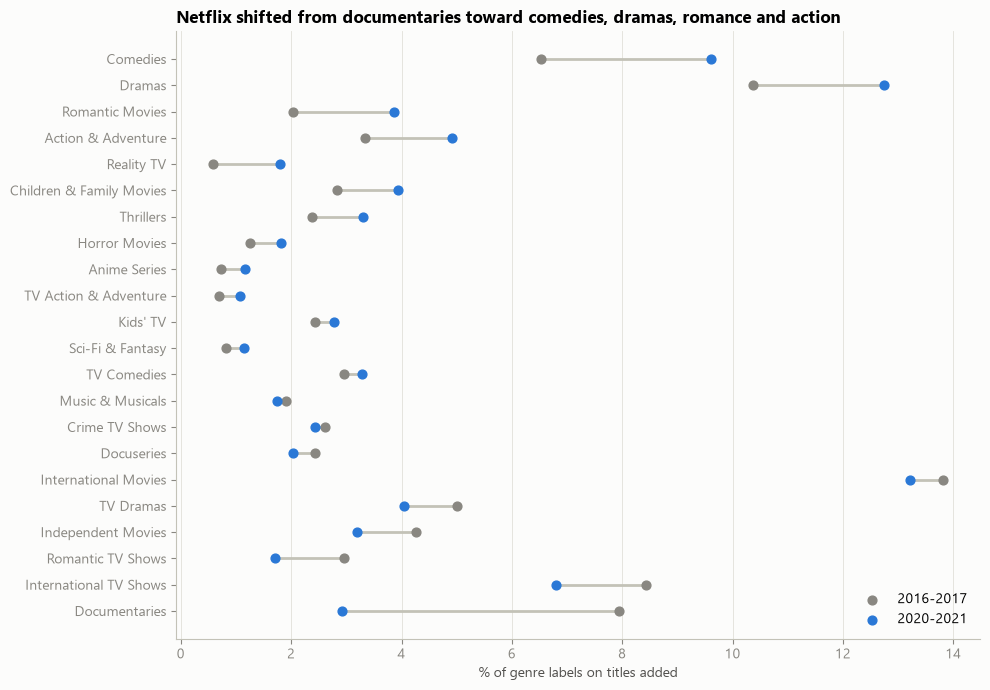

,pct_2016_2017,pct_2020_2021,titles_2020_2021,change_points
genre,,,,
Comedies,6.52,9.61,713,3.09
Dramas,10.37,12.75,946,2.38
Romantic Movies,2.03,3.87,287,1.84
Action & Adventure,3.33,4.92,365,1.59
Reality TV,0.58,1.81,134,1.23
Children & Family Movies,2.84,3.94,292,1.10
Thrillers,2.38,3.30,245,0.93
Horror Movies,1.25,1.82,135,0.57
Anime Series,0.72,1.16,86,0.43


In [3]:
title_genres = (
    study_years.assign(genre=study_years["listed_in"].str.split(","))
    .explode("genre")
    .assign(genre=lambda rows: rows["genre"].str.strip())
    .reset_index(drop=True)
)
early_share = title_genres.loc[title_genres["year_added"].isin([2016, 2017]), "genre"].value_counts(normalize=True)
late_genres = title_genres.loc[title_genres["year_added"].isin([2020, 2021]), "genre"]
genre_shift = pd.DataFrame({
    "pct_2016_2017": 100 * early_share,
    "pct_2020_2021": 100 * late_genres.value_counts(normalize=True),
    "titles_2020_2021": late_genres.value_counts(),
}).fillna(0).query("titles_2020_2021 >= 80")
genre_shift["change_points"] = genre_shift["pct_2020_2021"] - genre_shift["pct_2016_2017"]
genre_shift = genre_shift.sort_values("change_points")

fig, ax = plt.subplots(figsize=(10, 7))
y_positions = np.arange(len(genre_shift))
ax.hlines(y_positions, genre_shift["pct_2016_2017"], genre_shift["pct_2020_2021"], color="#c3c2b7", linewidth=2)
ax.scatter(genre_shift["pct_2016_2017"], y_positions, color="#898781", s=40, label="2016-2017", zorder=3)
ax.scatter(genre_shift["pct_2020_2021"], y_positions, color=SINGLE_SERIES_COLOR, s=40, label="2020-2021", zorder=3)
ax.set_yticks(y_positions, genre_shift.index)
ax.set_xlabel("% of genre labels on titles added")
ax.grid(axis="y", visible=False)
ax.set_title("Netflix shifted from documentaries toward comedies, dramas, romance and action")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

genre_shift.iloc[::-1].round(2)

In [4]:
freshness = study_years.groupby("year_added").agg(
    titles_added=("show_id", "size"),
    pct_recent_releases=("recent_release", lambda recent: 100 * recent.mean()),
    median_years_since_release=("release_year", lambda years: (study_years.loc[years.index, "year_added"] - years).median()),
)
freshness.round(1)

,titles_added,pct_recent_releases,median_years_since_release
year_added,,,
2016,429,65.5,1.0
2017,1188,59.8,1.0
2018,1649,54.8,1.0
2019,2015,51.7,1.0
2020,1879,55.5,1.0
2021,1494,50.9,1.0


## 3. IMDb ratings of what was added

Median IMDb rating by year added and type, for titles with at least 1,000 votes. Shaded bands are 95% bootstrap intervals for the median.

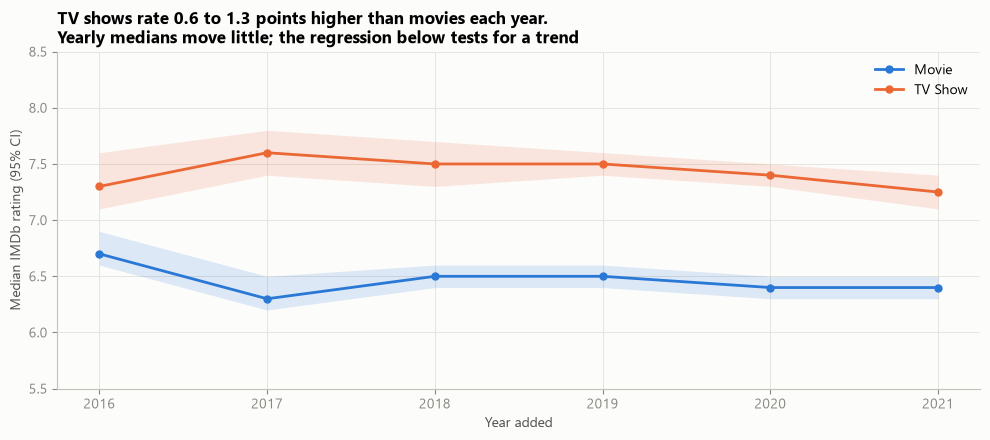

median_rating         titles        
type               Movie TV Show  Movie TV Show
year_added                                     
2016                 6.7    7.30  132.0    78.0
2017                 6.3    7.60  459.0   125.0
2018                 6.5    7.50  699.0   167.0
2019                 6.5    7.50  861.0   312.0
2020                 6.4    7.40  817.0   393.0
2021                 6.4    7.25  634.0   326.0

In [5]:
rated = study_years[study_years["imdb_votes"] >= MIN_IMDB_VOTES].copy()
generator = np.random.default_rng(0)


def bootstrap_median_ci(ratings, n_resamples=1000):
    medians = [np.median(generator.choice(ratings, size=len(ratings))) for _ in range(n_resamples)]
    return np.percentile(medians, [2.5, 97.5])


rating_rows = []
for (year_added, title_type), ratings in rated.groupby(["year_added", "type"])["imdb_rating"]:
    ci_low, ci_high = bootstrap_median_ci(ratings.to_numpy())
    rating_rows.append({"year_added": year_added, "type": title_type, "titles": len(ratings),
                        "median_rating": ratings.median(), "ci_low": ci_low, "ci_high": ci_high})
ratings_by_year = pd.DataFrame(rating_rows)

fig, ax = plt.subplots(figsize=(10, 4.5))
for title_type, color in TYPE_COLORS.items():
    rows = ratings_by_year[ratings_by_year["type"] == title_type]
    ax.plot(rows["year_added"], rows["median_rating"], marker="o", markersize=5, color=color, label=title_type)
    ax.fill_between(rows["year_added"], rows["ci_low"], rows["ci_high"], color=color, alpha=0.15, linewidth=0)
ax.set_ylim(5.5, 8.5)
ax.set_ylabel("Median IMDb rating (95% CI)")
ax.set_xlabel("Year added")
ax.set_title("TV shows rate 0.6 to 1.3 points higher than movies each year.\n"
             "Yearly medians move little; the regression below tests for a trend")
ax.legend()
plt.tight_layout()
plt.show()

ratings_by_year.pivot(index="year_added", columns="type", values=["median_rating", "titles"]).round(2)

Part of any change could come from the genre shift above, since documentaries tend to rate higher than comedies or romance. The regression estimates the change in rating by year added (2016 as reference) without and with genre controls. Both models control for type, log votes and recent release. Genres with at least 100 titles get their own indicator.

5,003 titles, 25 genre indicators


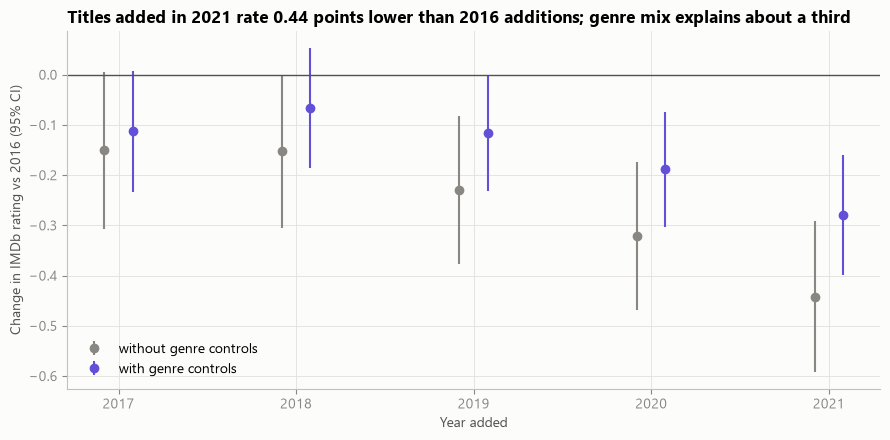

model,with genre controls,without genre controls
term,,
2017,-0.112,-0.150
2018,-0.066,-0.153
2019,-0.116,-0.230
2020,-0.188,-0.321
2021,-0.279,-0.442
recent release,-0.272,-0.174


In [6]:
genre_indicators = rated["listed_in"].str.get_dummies(sep=", ")
common_genres = genre_indicators.columns[genre_indicators.sum() >= 100]
genre_columns = {genre: "genre_" + "".join(character if character.isalnum() else "_" for character in genre)
                 for genre in common_genres}
rated_with_genres = rated.join(genre_indicators[common_genres].rename(columns=genre_columns))

base_formula = "imdb_rating ~ C(year_added) + C(type) + np.log(imdb_votes) + recent_release"
model_formulas = {
    "without genre controls": base_formula,
    "with genre controls": base_formula + " + " + " + ".join(genre_columns.values()),
}
year_effects = []
for model_name, formula in model_formulas.items():
    fitted_model = smf.ols(formula, data=rated_with_genres).fit(cov_type="HC1")
    conf_int = fitted_model.conf_int()
    for term in fitted_model.params.index:
        if term.startswith("C(year_added)") or term == "recent_release[T.True]":
            label = "recent release" if term.startswith("recent") else term.replace("C(year_added)[T.", "").rstrip("]")
            year_effects.append({"model": model_name, "term": label,
                                 "rating_change": fitted_model.params[term], "ci_low": conf_int.loc[term, 0],
                                 "ci_high": conf_int.loc[term, 1], "r_squared": fitted_model.rsquared})
year_effects = pd.DataFrame(year_effects)
print(f"{len(rated_with_genres):,} titles, {len(common_genres)} genre indicators")

model_colors = {"without genre controls": "#898781", "with genre controls": "#6250d6"}
fig, ax = plt.subplots(figsize=(9, 4.5))
for offset, (model_name, color) in zip([-0.08, 0.08], model_colors.items()):
    rows = year_effects[(year_effects["model"] == model_name) & (year_effects["term"] != "recent release")]
    years = rows["term"].astype(int).to_numpy()
    ax.errorbar(years + offset, rows["rating_change"],
                yerr=[rows["rating_change"] - rows["ci_low"], rows["ci_high"] - rows["rating_change"]],
                fmt="o", markersize=6, color=color, elinewidth=1.5, label=model_name)
ax.axhline(0, color=SECONDARY_INK, linewidth=1)
ax.set_xticks(range(2017, 2022))
ax.set_ylabel("Change in IMDb rating vs 2016 (95% CI)")
ax.set_xlabel("Year added")
ax.set_title("Titles added in 2021 rate 0.44 points lower than 2016 additions; genre mix explains about a third")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

year_effects.pivot(index="term", columns="model", values="rating_change").round(3)

## 4. Ratings by production country

Median IMDb rating by main production country and type, for countries with at least 30 rated titles of a type. The IMDb match rate is shown to check that countries were matched equally well.

In [7]:
all_rated = netflix[netflix["imdb_votes"] >= MIN_IMDB_VOTES]
country_ratings = all_rated.groupby(["main_country", "type"])["imdb_rating"].agg(titles="size", median_rating="median").unstack("type")
large_countries = country_ratings[(country_ratings[("titles", "Movie")] >= 30) | (country_ratings[("titles", "TV Show")] >= 30)].index
match_rate = 100 * netflix.groupby("main_country")["tconst"].apply(lambda ids: ids.notna().mean())
(
    country_ratings.loc[large_countries]
    .assign(imdb_match_rate_pct=match_rate.loc[large_countries])
    .sort_values(("titles", "Movie"), ascending=False)
    .round(2)
)

titles         median_rating         imdb_match_rate_pct
type             Movie TV Show         Movie TV Show                    
main_country                                                            
United States   1725.0   574.0           6.4    7.40               88.23
India            517.0    30.0           6.7    6.90               90.18
United Kingdom   273.0   137.0           6.7    7.60               87.40
Canada           108.0    54.0           6.0    7.35               87.82
France           105.0    42.0           6.4    7.25               91.04
Spain             89.0    33.0           6.2    7.10               85.08
Turkey            64.0    20.0           6.0    7.75               83.64
Germany           51.0    19.0           6.2    7.20               89.32
Japan             50.0   116.0           6.7    7.70               81.32
Australia         43.0    31.0           6.6    7.30               92.24
China             41.0    16.0           6.4    7.90               91.00
Hong Kong         38.0     NaN           6.6     NaN               85.90
Egypt             36.0     2.0           6.6    7.75               75.00
South Korea       36.0    91.0           6.6    7.80               87.20
Italy             34.0    13.0           6.2    6.80               89.55
Mexico            26.0    31.0           6.3    7.10               88.06

## Finding

**Netflix grew by adding more mainstream genres and, for a while, much more Indian content. The titles it added in 2020 and 2021 rate lower on IMDb, and the genre shift explains only part of that.**

- **Growth:** titles added rose from 429 in 2016 to 2,015 in 2019, then 1,879 in 2020 and 1,494 in the first nine months of 2021.
- **India's push:** India's share of additions went from 2.6% in 2016 to 20.6% in 2018, then fell back to 6.7% in 2021. The US share stayed between 30% and 42%; other countries rose to 52% of additions in 2021.
- **Genre shift:** comparing 2016-2017 with 2020-2021 additions, documentaries fell from 7.9% to 2.9% of genre labels, while comedies (+3.1 points), dramas (+2.4), romantic movies (+1.8), action (+1.6) and reality TV (0.6% to 1.8%) grew. Recent releases fell from 66% of additions to 51%.
- **Ratings:** TV shows rate 0.6 to 1.3 points higher than movies every year. Controlling for type, votes and recency, titles added in 2021 rate 0.44 points lower than 2016 additions (95% CI -0.59 to -0.29). Adding genre controls reduces this to 0.28 points (95% CI -0.40 to -0.16), so the genre shift explains about a third. With genre controls, only 2020 and 2021 are clearly below 2016.
- **Recent releases rate lower:** titles added within a year of release rate 0.27 points below older titles, other things equal. Older titles Netflix licenses are often already proven, so this is likely selection rather than lower quality of new content.
- **By country:** Indian movies have a median rating of 6.7, above US movies (6.4); Indian TV shows (6.9) rate below most countries' TV. IMDb match rates are similar across countries (75% to 92%), so matching does not drive these differences.

**Business answer.** Netflix's 2016 to 2021 growth came with a broader, more mainstream mix. The drop in average rating is real but modest (about a quarter to half a point) and only partly explained by genre, which fits a strategy of more volume over fewer acclaimed titles.

**Limitations**

- The catalog is a September 2021 snapshot; titles removed before then are missing, so earlier years are undercounted and filtered toward titles Netflix kept.
- Ratings are from 2026 and only cover matched titles with at least 1,000 votes (5,003 titles).
- Main country is the first listed production country, and genres are Netflix's own labels.